# 03. Финальная fused модель

**Цель.** Зафиксировать финальную мультимодальную HADES-like модель `hades_v2_strict_intensity_gap10`, показать ключевые метрики и экспортировать bundle для дашборда.


## 1. Инициализация

**Вопрос.** Какая модель считается финальной?


In [1]:
from pathlib import Path
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path.cwd()
OUT_DIR = ROOT / "outputs" / "final_notebooks"
OUT_DIR.mkdir(parents=True, exist_ok=True)

RAW_CONTRACT_PATH = ROOT / "outputs" / "raw_multirate" / "aligned_multirate_windows.csv"
STRICT_DIR = ROOT / "outputs" / "hades_like_v2" / "hades_v2_strict_intensity_gap10"
FINAL_ALERT_DIR = ROOT / "outputs" / "final_alert_system"

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

print("SEED =", SEED)
print("Выходная папка:", OUT_DIR)


SEED = 42
Выходная папка: C:\Main\DGTU\ВКР\Diploma\outputs\final_notebooks


**Локальный вывод.** В финальный контур включена лучшая проверенная постановка; промежуточные конфигурации сохранены вне основного документа.


## 2. Финальная постановка

Модель получает логи, KPI и маски доступности модальностей. Решение является единым fused score, а log-only и KPI-only остаются только baseline.

Главный score для дашборда: `warning_intensity_score`.

Диагностический strict risk-channel: `state_score = max(0.65 * warning_intensity_score, risk_intensity_score)`.


In [2]:
architecture = pd.DataFrame([
    {"блок": "log branch", "роль": "частоты событий, текстовые признаки, EmbeddingGemma"},
    {"блок": "KPI branch", "роль": "последовательности метрик и физическое состояние"},
    {"блок": "modality masks", "роль": "доступность логов/KPI как явный вход"},
    {"блок": "fusion block", "роль": "единое мультимодальное решение"},
    {"блок": "intensity heads", "роль": "нарастание риска по lead time"},
])
architecture


,блок,роль
0,log branch,"частоты событий, текстовые признаки, Embedding..."
1,KPI branch,последовательности метрик и физическое состояние
2,modality masks,доступность логов/KPI как явный вход
3,fusion block,единое мультимодальное решение
4,intensity heads,нарастание риска по lead time


**Локальный вывод.** Intensity нужен потому, что бинарный `risk` слишком жесткий для раннего предупреждения.


## 3. Итоговые метрики

**Вопрос.** Почему эта модель идет в dashboard?


In [3]:
ensemble = pd.read_csv(STRICT_DIR / "ensemble_metrics.csv")
baseline = pd.read_csv(STRICT_DIR / "baseline_comparison.csv")
ranking = pd.read_csv(STRICT_DIR / "ranking_diagnostics.csv")

warning_row = ensemble.loc[
    (ensemble["target"].eq("y_warning")) & (ensemble["score"].eq("warning_intensity_score"))
].iloc[0]
risk_row = ensemble.loc[
    (ensemble["target"].eq("y_risk")) & (ensemble["score"].eq("state_score"))
].iloc[0]
best_warning = baseline.loc[baseline["target"].eq("y_warning")].sort_values("average_precision", ascending=False).iloc[0]
best_risk = baseline.loc[baseline["target"].eq("y_risk")].sort_values("average_precision", ascending=False).iloc[0]

final_metrics = pd.DataFrame([
    {
        "цель": "warning / раннее предупреждение",
        "score": "warning_intensity_score",
        "AP модели": warning_row["average_precision"],
        "лучший baseline": best_warning["baseline"],
        "AP baseline": best_warning["average_precision"],
        "дельта AP": warning_row["average_precision"] - best_warning["average_precision"],
    },
    {
        "цель": "strict risk-channel",
        "score": "state_score",
        "AP модели": risk_row["average_precision"],
        "лучший baseline": best_risk["baseline"],
        "AP baseline": best_risk["average_precision"],
        "дельта AP": risk_row["average_precision"] - best_risk["average_precision"],
    },
])
final_metrics


,цель,score,AP модели,лучший baseline,AP baseline,дельта AP
0,warning / раннее предупреждение,warning_intensity_score,0.575633,kpi-only,0.453644,0.121988
1,strict risk-channel,state_score,0.157095,availability-only,0.141823,0.015272


In [4]:
topk = ranking.loc[
    (ranking["split"].eq("test"))
    & (ranking["top_fraction"].isin([0.05, 0.10]))
    & (
        ((ranking["target"].eq("y_warning")) & (ranking["score"].eq("warning_intensity_score")))
        | ((ranking["target"].eq("y_risk")) & (ranking["score"].eq("state_score")))
    )
].copy()
topk = topk[[
    "target", "score", "top_fraction", "precision_at_top",
    "lift_vs_prevalence", "detected_positive_run_share", "false_alarm_runs_without_target"
]]
topk


,target,score,top_fraction,precision_at_top,lift_vs_prevalence,detected_positive_run_share,false_alarm_runs_without_target
25,y_warning,warning_intensity_score,0.05,0.7500,1.857477,0.173913,3
26,y_warning,warning_intensity_score,0.10,0.7125,1.764603,0.304348,4
34,y_risk,state_score,0.05,0.1750,1.480053,0.173913,3
35,y_risk,state_score,0.10,0.2250,1.902926,0.304348,4


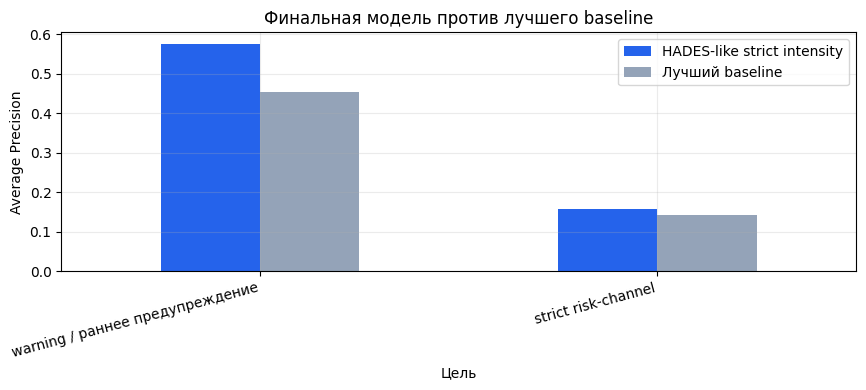

In [5]:
ax = final_metrics.set_index("цель")[["AP модели", "AP baseline"]].plot(kind="bar", color=["#2563eb", "#94a3b8"])
ax.set_title("Финальная модель против лучшего baseline")
ax.set_ylabel("Average Precision")
ax.set_xlabel("Цель")
ax.legend(["HADES-like strict intensity", "Лучший baseline"])
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


**Что показано.** Две ключевые метрики без перегруза промежуточными экспериментами.

**Что наблюдается.** `warning_intensity_score` дает явный выигрыш над baseline. `state_score` для strict risk остается слабым, но немного выше лучшей нижней границы.

**Локальный вывод.** В dashboard главным графиком должна быть оценка модели для alert-layer, а не обещание идеального бинарного предсказания аварии.


## 4. Ограничения

**Вопрос.** Что нельзя обещать по этой модели?


In [6]:
limitations = pd.DataFrame([
    {"ограничение": "strict risk-channel слабый", "следствие": "не продавать как бинарный оракул аварий"},
    {"ограничение": "порог 0.5 не продуктовый", "следствие": "порог тревоги выбирается alert-layer на validation"},
    {"ограничение": "логи могут содержать поздние симптомы", "следствие": "нужны gap, lead time и run-level replay"},
    {"ограничение": "это лабораторный replay", "следствие": "не production-ready, но pipeline заменяем и измерим"},
])
limitations


,ограничение,следствие
0,strict risk-channel слабый,не продавать как бинарный оракул аварий
1,порог 0.5 не продуктовый,порог тревоги выбирается alert-layer на valida...
2,логи могут содержать поздние симптомы,"нужны gap, lead time и run-level replay"
3,это лабораторный replay,"не production-ready, но pipeline заменяем и из..."


**Локальный вывод.** Защитная формулировка: это HADES-inspired replay-прототип раннего предупреждения, а не полноценная копия HADES.


## 5. Экспорт для дашборда

**Вопрос.** Какие файлы реально использует интерфейс?


In [7]:
from dashboard.export_strict_intensity_bundle import export_bundle

report = export_bundle()
dashboard_files = [
    FINAL_ALERT_DIR / "replay_bundle.csv.gz",
    FINAL_ALERT_DIR / "dashboard_model_report.json",
    FINAL_ALERT_DIR / "baseline_comparison.csv",
    FINAL_ALERT_DIR / "alert_events.csv",
    FINAL_ALERT_DIR / "metrics_summary.csv",
    FINAL_ALERT_DIR / "model_card_product.md",
]
file_table = pd.DataFrame([
    {
        "файл": str(path.relative_to(ROOT)),
        "существует": bool(path.exists()),
        "размер KB": round(path.stat().st_size / 1024, 1) if path.exists() else np.nan,
    }
    for path in dashboard_files
])
file_table


,файл,существует,размер KB
0,outputs\final_alert_system\replay_bundle.csv.gz,True,3920.4
1,outputs\final_alert_system\dashboard_model_rep...,True,3.6
2,outputs\final_alert_system\baseline_comparison...,True,0.8
3,outputs\final_alert_system\alert_events.csv,True,7.2
4,outputs\final_alert_system\metrics_summary.csv,True,0.3
5,outputs\final_alert_system\model_card_product.md,True,1.2


In [8]:
final_metrics_path = OUT_DIR / "final_model_metrics.csv"
model_card_path = OUT_DIR / "final_model_card.md"

final_metrics.to_csv(final_metrics_path, index=False)
model_card = "\n".join([
    "# Финальная модель",
    "",
    "Финальная модель: HADES-like strict intensity fusion.",
    "",
    f"- warning_intensity_score AP: {warning_row['average_precision']:.4f}",
    f"- лучший warning baseline: {best_warning['baseline']} AP={best_warning['average_precision']:.4f}",
    f"- state_score risk AP: {risk_row['average_precision']:.4f}",
    f"- лучший risk baseline: {best_risk['baseline']} AP={best_risk['average_precision']:.4f}",
    "",
    "Модель используется в dashboard через alert-layer: score модели отделен от состояния тревоги и факта инцидента.",
])
model_card_path.write_text(model_card, encoding="utf-8")

print("Записаны артефакты:")
print("-", final_metrics_path.relative_to(ROOT))
print("-", model_card_path.relative_to(ROOT))
print("Dashboard bundle:")
for path in dashboard_files:
    print("-", path.relative_to(ROOT))


Записаны артефакты:
- outputs\final_notebooks\final_model_metrics.csv
- outputs\final_notebooks\final_model_card.md
Dashboard bundle:
- outputs\final_alert_system\replay_bundle.csv.gz
- outputs\final_alert_system\dashboard_model_report.json
- outputs\final_alert_system\baseline_comparison.csv
- outputs\final_alert_system\alert_events.csv
- outputs\final_alert_system\metrics_summary.csv
- outputs\final_alert_system\model_card_product.md


**Итоговый вывод.** Финальный контур: strict/intensity мультимодальная модель → alert-layer → replay bundle → dashboard. Модель не скрывает ограничения risk-channel, но дает защищаемый выигрыш по раннему warning/intensity ranking и запускаемый демонстрационный контур.
